# Diabetes Health Indicators — Simplified

BRFSS 2021 binary classification: Diabetes_binary (0 = no diabetes/prediabetes, 1 = diabetes).

Steps: EDA → balance the training data → XGBoost vs. Logistic Regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "Diabetes_binary"
pd.set_option("display.max_columns", None)

## 1. Load data
Columns are stored as floats, so they are cast to `int`.

In [2]:
df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2021.csv").astype(int)
print("Original shape:", df.shape)
display(df.head())

Original shape: (236378, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,15,1,0,0,0,1,1,0,1,0,5,10,20,0,0,11,4,5
1,1,1,0,1,28,0,0,1,0,1,0,0,1,0,2,0,0,0,0,11,4,3
2,1,1,1,1,33,0,0,0,1,1,1,0,1,0,2,10,0,0,0,9,4,7
3,1,0,1,1,29,0,1,1,1,1,1,0,1,0,5,0,30,1,1,12,3,4
4,0,0,0,1,24,1,0,0,0,0,0,0,1,0,3,0,0,1,1,13,5,6


## 2. Data quality

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values: 0
Exact duplicate rows: 13135


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,236378.0,0.142010,0.349061,0.0,0.0,0.0,0.0,1.0
HighBP,236378.0,0.418558,0.493324,0.0,0.0,0.0,1.0,1.0
HighChol,236378.0,0.402059,0.490315,0.0,0.0,0.0,1.0,1.0
CholCheck,236378.0,0.963347,0.187909,0.0,1.0,1.0,1.0,1.0
BMI,236378.0,28.953579,6.552055,12.0,24.0,28.0,32.0,99.0
Smoker,236378.0,0.411997,0.492196,0.0,0.0,0.0,1.0,1.0
Stroke,236378.0,0.038900,0.193356,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,236378.0,0.086548,0.281172,0.0,0.0,0.0,0.0,1.0
PhysActivity,236378.0,0.779231,0.414766,0.0,1.0,1.0,1.0,1.0
Fruits,236378.0,0.621259,0.485074,0.0,0.0,1.0,1.0,1.0


No missing values. 13,135 exact duplicates (5.6%), removed so the same row can't be in both train and test.

In [4]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

FEATURES = [c for c in df.columns if c != TARGET]
X = df[FEATURES]
y = df[TARGET]

print("Shape after removing duplicates:", df.shape)
print("Diabetes rate:", round(y.mean() * 100, 2), "%")
print(y.value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))

Shape after removing duplicates: (223243, 22)
Diabetes rate: 14.96 %
Diabetes_binary
No diabetes    189848
Diabetes        33395
Name: count, dtype: int64


## 3. Target distribution

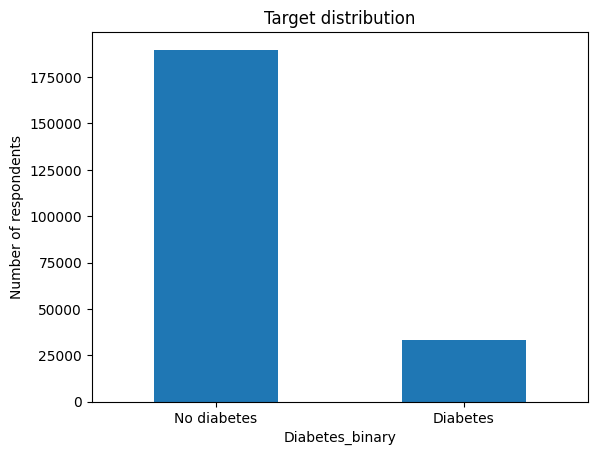

In [5]:
# Target balance
y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
plt.ylabel("Number of respondents")
plt.title("Target distribution")
plt.show()

Imbalanced (85% / 15%), so accuracy is misleading. The training data is balanced in section 8.

## 4. Univariate analysis

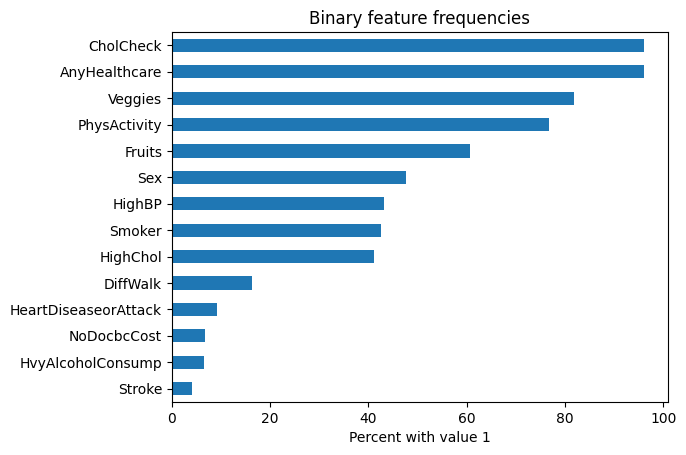

In [6]:
# Percentage of respondents with value 1 for binary features
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]
(df[binary_features].mean().sort_values() * 100).plot(kind="barh")
plt.xlabel("Percent with value 1")
plt.title("Binary feature frequencies")
plt.show()

Near-constant: CholCheck and AnyHealthcare (96% = 1), Stroke (4%), HvyAlcoholConsump (6%).

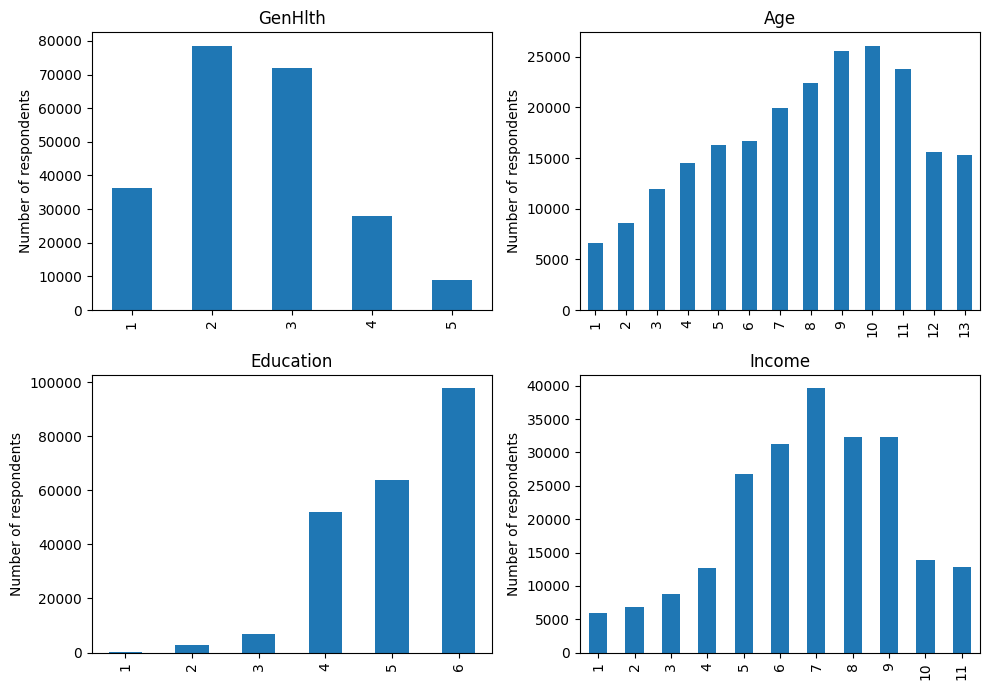

In [7]:
# Distribution of ordinal features
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    df[col].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Number of respondents")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Mostly older (Age 8–11 = 55–74), well-educated respondents. Income peaks at level 7 ($50–75k).

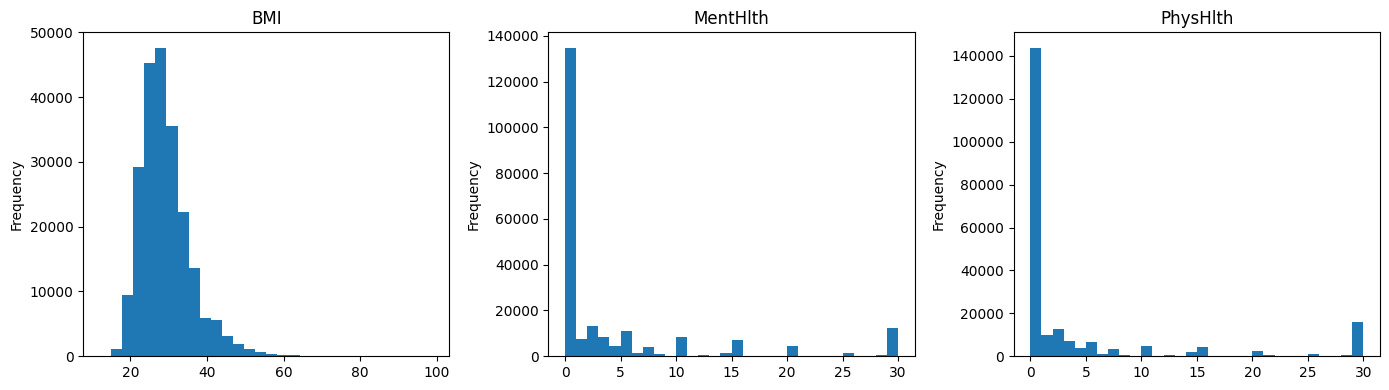

In [8]:
# Distribution of BMI and poor-health days
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    df[col].plot(kind="hist", bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

BMI is right-skewed (median 28). Values above 70 (124 rows) are kept, because trees are not affected by outliers. Most people report 0 poor-health days.

## 5. Bivariate analysis (feature vs. target)

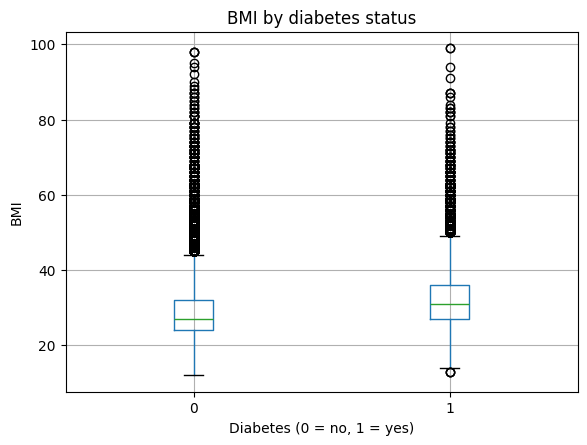

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0,189848.0,28.6,6.4,12.0,24.0,27.0,32.0,98.0
1,33395.0,32.2,7.4,13.0,27.0,31.0,36.0,99.0


In [9]:
# BMI distribution by target
df.boxplot(column="BMI", by=TARGET)
plt.xlabel("Diabetes (0 = no, 1 = yes)")
plt.ylabel("BMI")
plt.title("BMI by diabetes status")
plt.suptitle("")
plt.show()

display(df.groupby(TARGET)["BMI"].describe().round(1))

People with diabetes have a higher BMI (median 31 vs. 27).

,diabetes_rate_%
BMI_category,
Underweight,6.04
Normal,6.85
Overweight,12.41
Obesity I,18.75
Obesity II,24.16
Obesity III,30.31


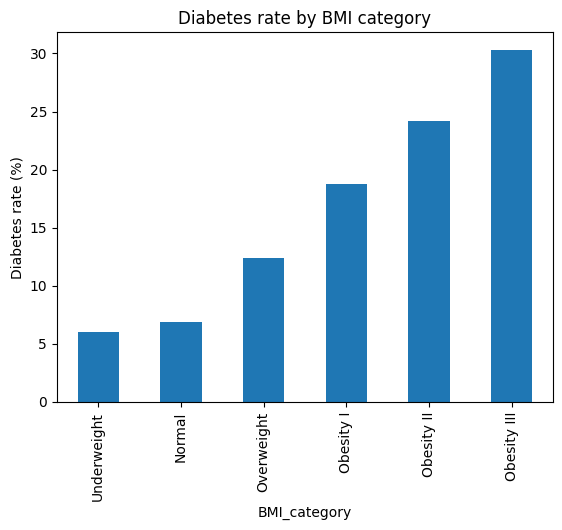

In [10]:
# BMI category and diabetes rate
df["BMI_category"] = pd.cut(
    df["BMI"], bins=[0, 18.5, 25, 30, 35, 40, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obesity I", "Obesity II", "Obesity III"],
    right=False
)
display((df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).rename("diabetes_rate_%").round(2))
(df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).plot(kind="bar")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by BMI category")
plt.show()

The rate rises from about 7% (normal) to 30% (obesity III).

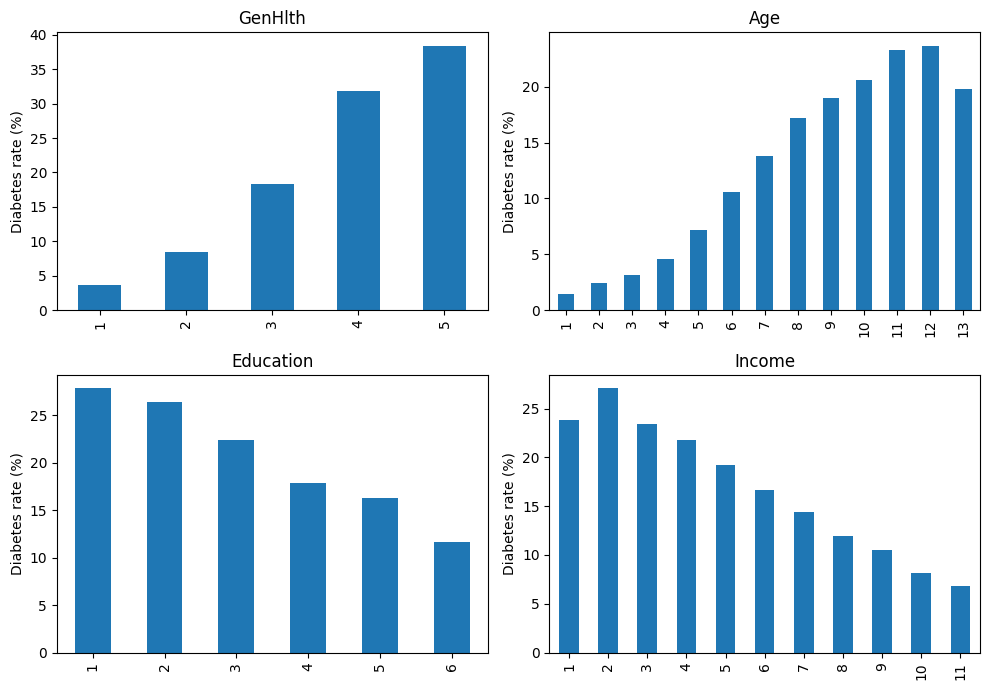

In [11]:
# Diabetes rate by each ordinal feature
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    (df.groupby(col, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Diabetes rate (%)")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

- The rate rises with worse general health (4% → 38%) and with age (peak 24% at 75–79).
- It falls with education (28% → 12%) and income (27% → 7%).

,rate_when_0_%,rate_when_1_%
feature,,
HeartDiseaseorAttack,13.03,34.21
Stroke,14.23,31.82
DiffWalk,11.77,31.37
HighBP,7.01,25.43
HighChol,9.17,23.26
Smoker,13.51,16.91
Sex,13.71,16.34
NoDocbcCost,14.88,15.99
CholCheck,1.94,15.48


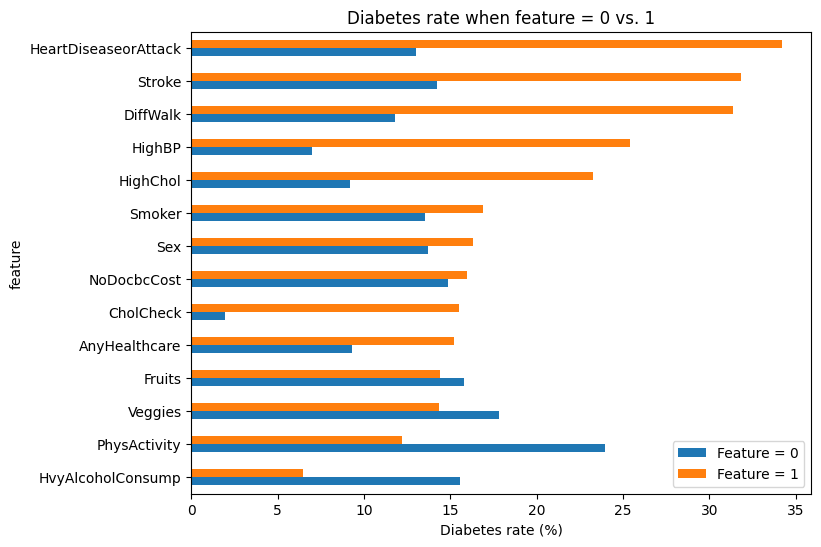

In [12]:
# Diabetes rate for feature values 0 and 1
rows = []
for col in binary_features:
    rates = df.groupby(col)[TARGET].mean()
    rows.append({
        "feature": col,
        "rate_when_0_%": rates.get(0, np.nan) * 100,
        "rate_when_1_%": rates.get(1, np.nan) * 100
    })

binary_rates = pd.DataFrame(rows).set_index("feature")
display(binary_rates.round(2).sort_values("rate_when_1_%", ascending=False))

binary_rates.sort_values("rate_when_1_%").plot(kind="barh", figsize=(8, 6))
plt.xlabel("Diabetes rate (%)")
plt.title("Diabetes rate when feature = 0 vs. 1")
plt.legend(["Feature = 0", "Feature = 1"])
plt.show()

- Strongest: HeartDiseaseorAttack, Stroke, DiffWalk, HighBP, HighChol (2.2–3.6× higher rate when = 1).
- PhysActivity and HvyAlcoholConsump go with lower rates.

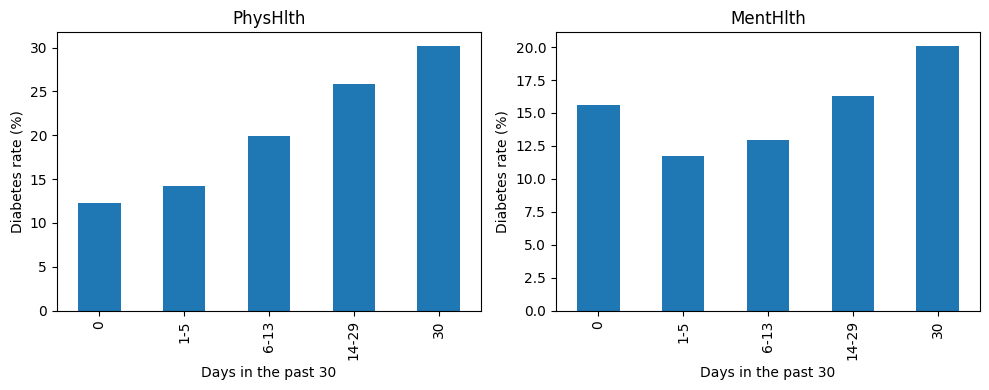

In [13]:
# Diabetes rate by number of poor-health days
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["PhysHlth", "MentHlth"]):
    days = pd.cut(df[col], bins=[-1, 0, 5, 13, 29, 30], labels=["0", "1-5", "6-13", "14-29", "30"])
    (df.groupby(days, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Days in the past 30")
    ax.set_ylabel("Diabetes rate (%)")
plt.tight_layout()
plt.show()

PhysHlth matters (12% → 30%). MentHlth is weak and not steady.

## 6. Correlation

,Diabetes_binary
GenHlth,0.265
HighBP,0.256
DiffWalk,0.203
HighChol,0.194
BMI,0.193
Age,0.192
HeartDiseaseorAttack,0.171
Income,-0.139
PhysActivity,-0.139
PhysHlth,0.128


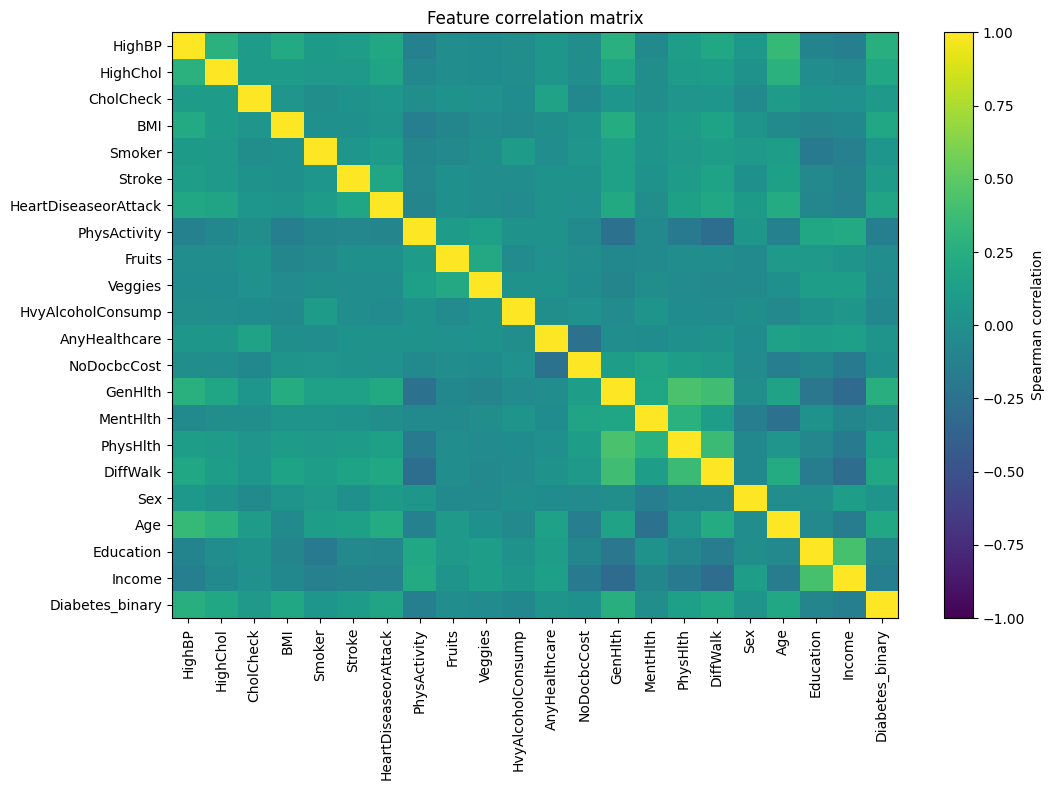

In [14]:
# Spearman correlations
corr = df[FEATURES + [TARGET]].corr(method="spearman")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

Correlations with the target are modest (max 0.265, GenHlth and HighBP). No feature pair is above 0.42, so there's no multicollinearity.

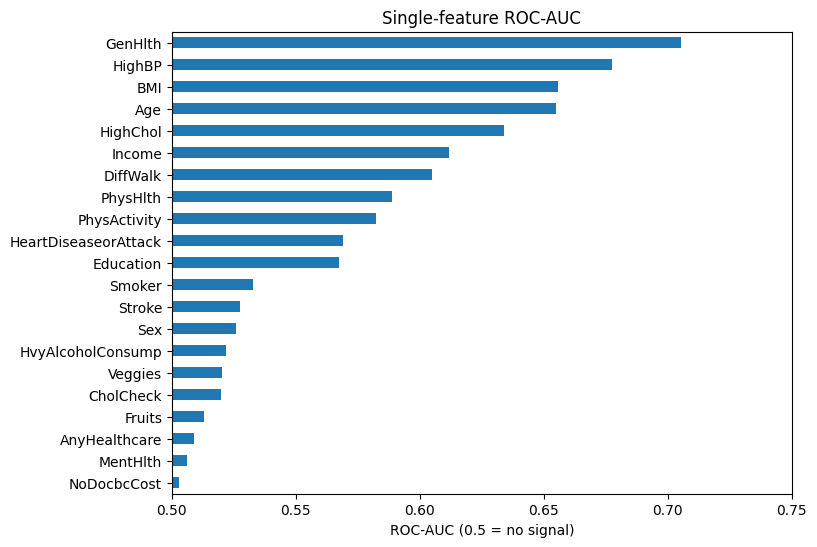

In [15]:
# Leakage check: ROC-AUC of each feature on its own
auc = pd.Series({c: roc_auc_score(df[TARGET], df[c]) for c in FEATURES})
auc = np.maximum(auc, 1 - auc).sort_values()   # strength in either direction
auc.plot(kind="barh", figsize=(8, 6), xlim=(0.5, 0.75))
plt.xlabel("ROC-AUC (0.5 = no signal)")
plt.title("Single-feature ROC-AUC")
plt.show()

The best single feature (GenHlth) reaches only 0.70, so there's no leakage.

## 7. Multivariate analysis

,count,diabetes_rate
condition_count,,
0,86010,4.61
1,73357,13.48
2,49209,27.80
3,12825,38.85
4,1842,47.88


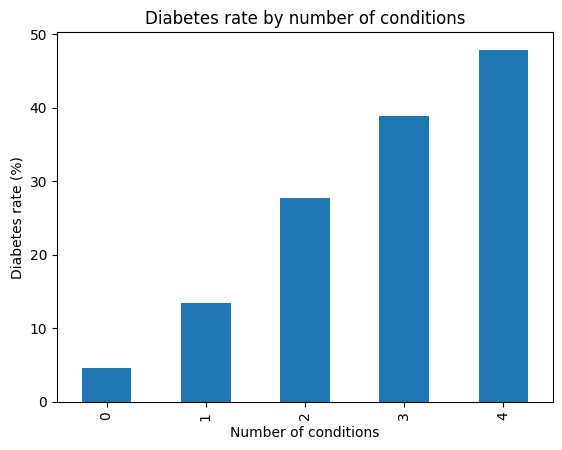

In [16]:
# Number of cardiometabolic conditions
conditions = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]
df["condition_count"] = df[conditions].sum(axis=1)
display(df.groupby("condition_count")[TARGET].agg(["count", "mean"]).rename(columns={"mean": "diabetes_rate"}).assign(
    diabetes_rate=lambda x: (x["diabetes_rate"] * 100).round(2)
))
(df.groupby("condition_count")[TARGET].mean() * 100).plot(kind="bar")
plt.xlabel("Number of conditions")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by number of conditions")
plt.show()

The rate rises with each extra condition: 5% (none) → 48% (all four).

BMI_category,Underweight,Normal,Overweight,Obesity I,Obesity II,Obesity III
Age,,,,,,
18-39,1.3,1.3,1.8,3.7,6.0,11.3
40-49,5.1,3.2,5.3,10.4,14.6,22.9
50-59,7.6,6.3,11.1,18.0,25.5,34.0
60-69,8.0,8.5,15.7,24.5,32.2,42.1
70+,7.9,12.2,20.6,29.5,38.5,45.0


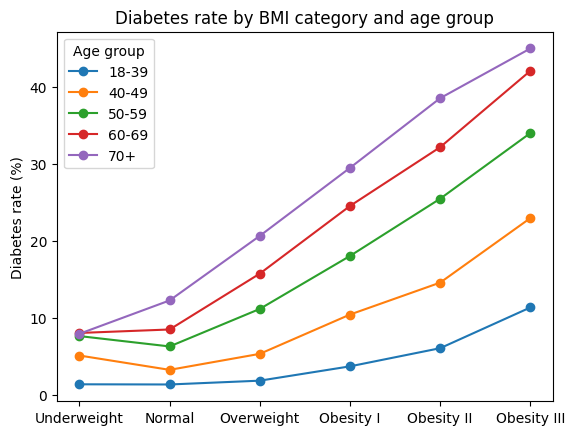

In [17]:
# Age group x BMI category
age_group = pd.cut(df["Age"], bins=[0, 4, 6, 8, 10, 13], labels=["18-39", "40-49", "50-59", "60-69", "70+"])
age_bmi = pd.crosstab(age_group, df["BMI_category"], values=df[TARGET], aggfunc="mean") * 100
display(age_bmi.round(1))

age_bmi.T.plot(marker="o")
plt.ylabel("Diabetes rate (%)")
plt.xlabel("")
plt.title("Diabetes rate by BMI category and age group")
plt.legend(title="Age group")
plt.show()

Age and BMI add up: about 1% (18–39, normal BMI) → 45% (70+, obesity III).

## 8. Balance the dataset
- Split first (80/20, stratified).
- Then undersample the training set: keep all diabetes rows and the same number of random no-diabetes rows.
- The test set keeps the real 85/15 ratio, so test scores stay honest.

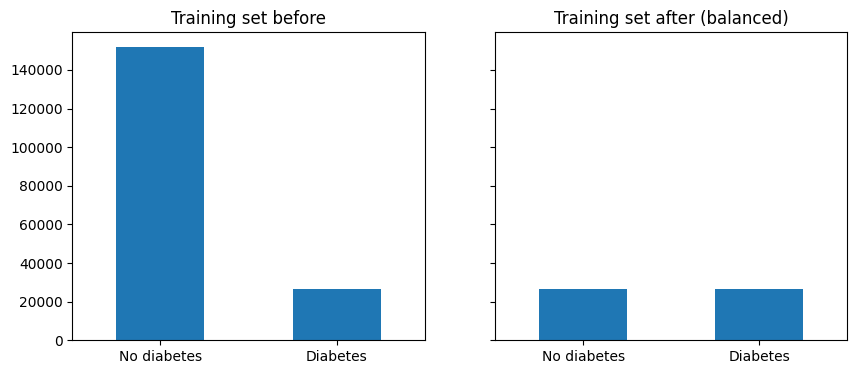

Train before: {0: 151878, 1: 26716}
Train after:  {0: 26716, 1: 26716}
Test (unchanged): {0: 37970, 1: 6679}


In [18]:
# Split (original 21 features only)
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Random undersampling of the training set
train = pd.concat([X_train, y_train], axis=1)
n_diabetes = (train[TARGET] == 1).sum()
train_bal = pd.concat([
    train[train[TARGET] == 1],
    train[train[TARGET] == 0].sample(n_diabetes, random_state=RANDOM_STATE)
]).sample(frac=1, random_state=RANDOM_STATE)   # shuffle
X_train_bal, y_train_bal = train_bal[FEATURES], train_bal[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
y_train.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Training set before")
y_train_bal.value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Training set after (balanced)")
for ax in axes:
    ax.set_xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
    ax.set_xlabel("")
plt.show()

print("Train before:", y_train.value_counts().to_dict())
print("Train after: ", y_train_bal.value_counts().to_dict())
print("Test (unchanged):", y_test.value_counts().to_dict())

## 9. Modelling
Each model gets a 5-fold CV ROC-AUC on its training data and is then scored on the real test set (threshold 0.5).

In [19]:
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, ConfusionMatrixDisplay)

results = {}   # name -> scores
probas = {}    # name -> predicted probabilities on the test set

def evaluate(name, model, X_tr, y_tr):
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=5, scoring="roc_auc").mean()
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {
        "CV ROC-AUC": cv_auc,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    }
    probas[name] = proba
    return pd.DataFrame(results).T.round(3)

### 9.1 XGBoost on the original (imbalanced) data
For comparison only: this shows why balancing is needed.

In [20]:
evaluate("XGBoost - imbalanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train, y_train)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.81,0.409,0.16,0.532,0.246,0.853


High accuracy (85%), but recall is only 16%: it misses most diabetics.

### 9.2 XGBoost on the balanced data

In [21]:
evaluate("XGBoost - balanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702


Recall jumps to 78% and F1 from 0.25 to 0.44. Precision drops, as expected.

### 9.3 XGBoost, balanced + better settings
Slower learning, smaller trees and subsampling, to reduce overfitting.

In [22]:
xgb_model = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              subsample=0.8, colsample_bytree=0.8,
                              random_state=RANDOM_STATE, n_jobs=-1)
evaluate("XGBoost - balanced + settings", xgb_model, X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.420,0.787,0.307,0.442,0.703


Best model: ROC-AUC rises from 0.806 to 0.814, and PR-AUC from 0.402 to 0.420.

### 9.4 Comparison model: Logistic Regression
A simple linear baseline (scaled features), trained on the same balanced data.

In [23]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
evaluate("Logistic Regression - balanced", log_reg, X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.420,0.787,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716


## 10. Results

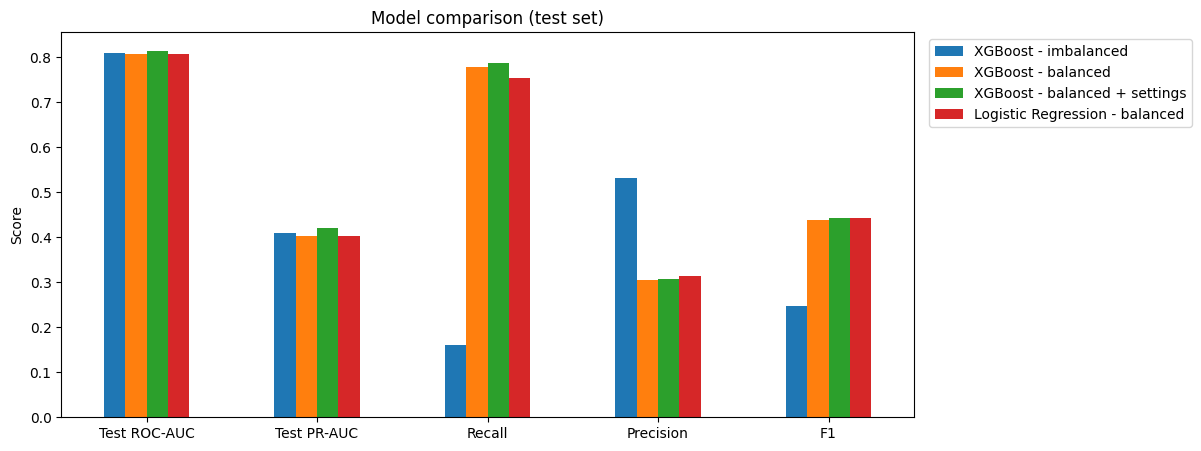

In [24]:
# Compare the models on the test set
metrics = ["Test ROC-AUC", "Test PR-AUC", "Recall", "Precision", "F1"]
pd.DataFrame(results).loc[metrics].plot(kind="bar", figsize=(11, 5))
plt.xticks(rotation=0)
plt.ylabel("Score")
plt.title("Model comparison (test set)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

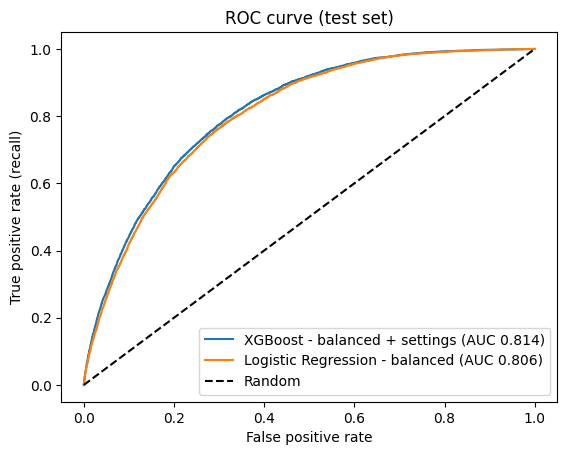

In [25]:
# ROC curves: best XGBoost vs. Logistic Regression
for name in ["XGBoost - balanced + settings", "Logistic Regression - balanced"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {results[name]['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

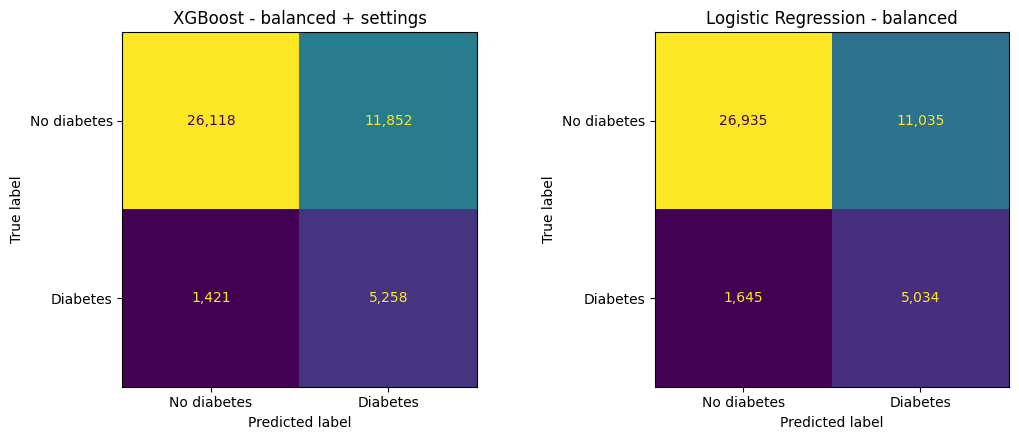

In [26]:
# Confusion matrices (test set)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["XGBoost - balanced + settings", "Logistic Regression - balanced"]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probas[name] >= 0.5).astype(int),
                                            display_labels=["No diabetes", "Diabetes"],
                                            ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout()
plt.show()

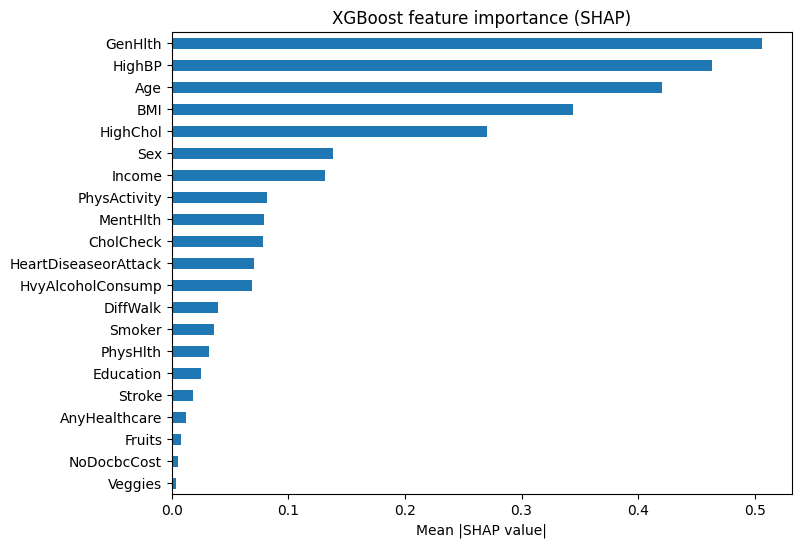

In [27]:
# Feature importance (best XGBoost): mean |SHAP value| on the test set
shap_values = xgb_model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]   # last column = bias
pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Mean |SHAP value|")
plt.title("XGBoost feature importance (SHAP)")
plt.show()

## 11. Conclusion
- Balancing the training data was the biggest improvement: recall went from 16% to 78%.
- Best model: XGBoost (balanced + settings). Test ROC-AUC 0.814, PR-AUC 0.420, recall 79%, F1 0.44.
- Logistic Regression is close: same F1 (0.44), but lower ROC-AUC (0.806), PR-AUC (0.402) and recall (75%).
- Top features (SHAP): GenHlth, HighBP, Age, BMI, HighChol.